In [3]:
import os
import sys
import torch
import numpy as np
from datasets import load_from_disk
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments
)
from peft import LoraConfig, get_peft_model, TaskType

# Automatic Colab mount vs Local detection
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROCESSED_DIR = '/content/drive/MyDrive/lora/data/df-task'
    MODEL_OUTPUT_DIR = '/content/drive/MyDrive/lora/models'
else:
    PROCESSED_DIR = '../data/df-task'
    MODEL_OUTPUT_DIR = '../models'

os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
print(f"Running in Colab: {IN_COLAB} | Loading datasets from: {PROCESSED_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running in Colab: True | Loading datasets from: /content/drive/MyDrive/lora/data/df-task


In [ ]:
%pip install --upgrade torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 11.7 MB/s  0:00:00 eta 0:00:01
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


## 2. Configuration & Dataset Loading

In [20]:
# Experiment Hyperparameters & Settings
LANG = 'eng'  # Target language: English
INPUT_FORMAT = 'input_v2_features_first'  # Choices: 'input_v1_prefix', 'input_v2_features_first', 'input_v3_sigmorphon', 'input_v4_instruction'
MODEL_NAME = 'google/byt5-small'
MAX_LENGTH = 64
BATCH_SIZE = 16
EPOCHS = 3
LEARNING_RATE = 3e-3  # LoRA typically benefits from slightly higher learning rates than full fine-tuning

# LoRA Hyperparameters
LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.1
TARGET_MODULES = ["q", "k", "v", "o", "wi_0", "wi_1", "wo"] 
# NOTE: Expanding LORA to all target models is backed by paper evidence: LoRA (QLoRA / Detmers et al.).

# Load pre-processed English dataset splits
dataset_path = os.path.join(PROCESSED_DIR, f'{LANG}_inflection')
dataset = load_from_disk(dataset_path)
print(f"Loaded dataset for language '{LANG}':", dataset)

Loaded dataset for language 'eng': DatasetDict({
    train: Dataset({
        features: ['lemma', 'target', 'features', 'input_v1_prefix', 'input_v2_features_first', 'input_v3_sigmorphon', 'input_v4_instruction', 'target_text'],
        num_rows: 521740
    })
    val: Dataset({
        features: ['lemma', 'target', 'features', 'input_v1_prefix', 'input_v2_features_first', 'input_v3_sigmorphon', 'input_v4_instruction', 'target_text'],
        num_rows: 65222
    })
    test: Dataset({
        features: ['lemma', 'target', 'features', 'input_v1_prefix', 'input_v2_features_first', 'input_v3_sigmorphon', 'input_v4_instruction', 'target_text'],
        num_rows: 65506
    })
})


## 3. Tokenization & LoRA Model Wrapping

In [14]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def preprocess_function(examples):
    inputs = examples[INPUT_FORMAT]
    targets = examples['target_text']
    
    model_inputs = tokenizer(inputs, max_length=MAX_LENGTH, truncation=True)
    labels = tokenizer(text_target=targets, max_length=MAX_LENGTH, truncation=True)
    
    model_inputs['labels'] = labels['input_ids']
    return model_inputs

num_cores = os.cpu_count() or 2
print(f"Tokenizing dataset using {num_cores} CPU cores...")

tokenized_dataset = dataset.map(
    preprocess_function,
    batched=True,
    num_proc=num_cores,
    remove_columns=dataset['train'].column_names
)

# Function to build fresh base model wrapped with LoRA adapter
def create_lora_model():
    base_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
    peft_config = LoraConfig(
        task_type=TaskType.SEQ_2_SEQ_LM,
        r=LORA_R,
        lora_alpha=LORA_ALPHA,
        target_modules=TARGET_MODULES,
        lora_dropout=LORA_DROPOUT,
        bias="none", 
    )
    lora_model = get_peft_model(base_model, peft_config)
    return lora_model

model = create_lora_model()
model.print_trainable_parameters()

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    pad_to_multiple_of=8
)

Tokenizing dataset using 2 CPU cores...


Loading weights:   0%|          | 0/172 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


trainable params: 6,258,688 || all params: 305,896,448 || trainable%: 2.0460


## 4. Sanity Testing Pipeline

In [15]:
# TEST 1: Micro-Batch Overfitting Check
# Verifies that LoRA low-rank adapter matrices can overfit and learn on 32 samples
print("=== TEST 1: Overfitting on Micro-Batch (32 samples) ===")
debug_dataset = tokenized_dataset['train'].select(range(min(32, len(tokenized_dataset['train']))))

debug_args = Seq2SeqTrainingArguments(
    output_dir='./debug_output',
    num_train_epochs=100,
    per_device_train_batch_size=32,
    learning_rate=1e-3,
    logging_steps=20,
    save_strategy='no',
    report_to='none'
)

debug_trainer = Seq2SeqTrainer(
    model=model,
    args=debug_args,
    train_dataset=debug_dataset,
    data_collator=data_collator,
    processing_class=tokenizer
)

debug_trainer.train()
print("Overfitting test complete. Loss should be near 0.0.")

=== TEST 1: Overfitting on Micro-Batch (32 samples) ===


Step,Training Loss
20,2.935131
40,0.574385
60,0.189916
80,0.127229
100,0.104376


Overfitting test complete. Loss should be near 0.0.


In [16]:
# TEST 2: Model Output Decoding Check
print("=== TEST 2: Model Output Decoding Check ===")
model.eval()
sample_eval = tokenized_dataset['val'].select(range(10))

padded_inputs = tokenizer.pad(
    {'input_ids': sample_eval['input_ids']},
    return_tensors='pt'
)
input_ids = padded_inputs['input_ids'].to(model.device)

with torch.no_grad():
    generated_ids = model.generate(input_ids=input_ids, max_length=MAX_LENGTH)

decoded_preds = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)
for idx, pred in enumerate(decoded_preds):
    print(f"Sample {idx+1} | Target: '{dataset['val']['target_text'][idx]}' | Predicted: '{pred}'")

=== TEST 2: Model Output Decoding Check ===
Sample 1 | Target: 'organotropisms' | Predicted: 'organotropisms'
Sample 2 | Target: 'tacklehouses' | Predicted: 'tacklehouses'
Sample 3 | Target: 'dununs' | Predicted: 'dununs'
Sample 4 | Target: 'organotropisms' | Predicted: 'organotropisms'
Sample 5 | Target: 'tacklehouses' | Predicted: 'tacklehouses'
Sample 6 | Target: 'dununs' | Predicted: 'dununs'
Sample 7 | Target: 'overnims' | Predicted: 'overniming'
Sample 8 | Target: 'overnimming' | Predicted: 'overnimiming'
Sample 9 | Target: 'overnam' | Predicted: 'overniming'
Sample 10 | Target: 'overnum' | Predicted: 'overnimes'


In [17]:
# TEST 3: Pipeline Evaluation Dry-Run
print("=== TEST 3: Pipeline Evaluation Dry-Run ===")
dry_val_dataset = tokenized_dataset['val'].select(range(min(50, len(tokenized_dataset['val']))))

dry_args = Seq2SeqTrainingArguments(
    output_dir='./dry_run_output',
    per_device_eval_batch_size=16,
    predict_with_generate=True,
    report_to='none',
    save_strategy='no'
)

dry_trainer = Seq2SeqTrainer(
    model=model,
    args=dry_args,
    eval_dataset=dry_val_dataset,
    data_collator=data_collator,
    processing_class=tokenizer
)

dry_eval_results = dry_trainer.evaluate()
print("Dry-run evaluation metrics:", dry_eval_results)

=== TEST 3: Pipeline Evaluation Dry-Run ===


Training Loss,Validation Loss,Step
No log,0.286338,0


Dry-run evaluation metrics: {'eval_loss': 0.2863382399082184}


## 5. Full LoRA Experiment Execution

In [ ]:
def compute_metrics(eval_preds):
    preds, labels = eval_preds
    
    if isinstance(preds, tuple):
       preds = preds[0]
       
    # Replace -100 in labels so hf tokenizer can decode properly
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    
    # 2. Clean predictions (-100 or negative IDs -> pad_token_id)
    preds = np.where(preds >= 0, preds, tokenizer.pad_token_id)
    
    # TODO: Understand hf vs pytorch stuff
    
    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    
    decoded_preds = [p.strip() for p in decoded_preds]
    decoded_labels = [l.strip() for l in decoded_labels]
    
    exact_match = sum(p == l for p, l in zip(decoded_preds, decoded_labels)) / len(decoded_preds)
    
    return {
        "exact_match": exact_match
    }
    

In [27]:
# 1. Hyperparameter Tweaks for Medium Run
BATCH_SIZE = 32               # Bump batch size to 32 to maximize GPU utilization & speed up epochs
LEARNING_RATE = 3e-3          # Proven optimal LR for expanded LoRA target modules
EPOCHS = 3                    # 3 epochs gives a clear convergence trajectory

# 2. Reload fresh LoRA weights
model = create_lora_model()

# 3. Create a Substantial Data Slice (10,000 train / 2,000 val)
train_subset = tokenized_dataset['train'].shuffle(seed=42).select(range(10000))
val_subset = tokenized_dataset['val'].select(range(2000))

output_dir_name = f"{LANG}_{MODEL_NAME.replace('/', '_')}_{INPUT_FORMAT}_lora_10k"

training_args = Seq2SeqTrainingArguments(
    output_dir=os.path.join(MODEL_OUTPUT_DIR, output_dir_name),
    
    # Evaluation & Logging
    eval_strategy='epoch',
    save_strategy='epoch',            # Save checkpoint at the end of each epoch
    save_total_limit=1,               # Keep only the best/latest checkpoint to conserve Drive space
    load_best_model_at_end=True,      # Automatically restore the best model weights after training
    metric_for_best_model='exact_match', # Track EM accuracy to select the best model
    greater_is_better=True,
    logging_steps=10,                 # Log every 10 steps to see smooth real-time loss curves
    
    # Optimization
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2, # Eval doesn't need backward pass memory, double it!
    num_train_epochs=EPOCHS,
    
    # Generation Settings
    predict_with_generate=True,
    generation_max_length=MAX_LENGTH,
    
    # Precision
    fp16=False,
    bf16=torch.cuda.is_bf16_supported()
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_subset,
    eval_dataset=val_subset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print(f"Starting substantial LoRA run (10k samples) for '{LANG}' using format '{INPUT_FORMAT}'...")
trainer.train()

Loading weights:   0%|          | 0/172 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Starting substantial LoRA run (10k samples) for 'eng' using format 'input_v2_features_first'...


Epoch,Training Loss,Validation Loss,Exact Match
1,0.036081,0.061751,0.909500
2,0.027861,0.039297,0.940500
3,0.026010,0.032511,0.955000


TrainOutput(global_step=939, training_loss=0.0766688746036178, metrics={'train_runtime': 783.0656, 'train_samples_per_second': 38.311, 'train_steps_per_second': 1.199, 'total_flos': 1688122786086912.0, 'train_loss': 0.0766688746036178, 'epoch': 3.0})

## 6. Training & Validation Loss Visualization

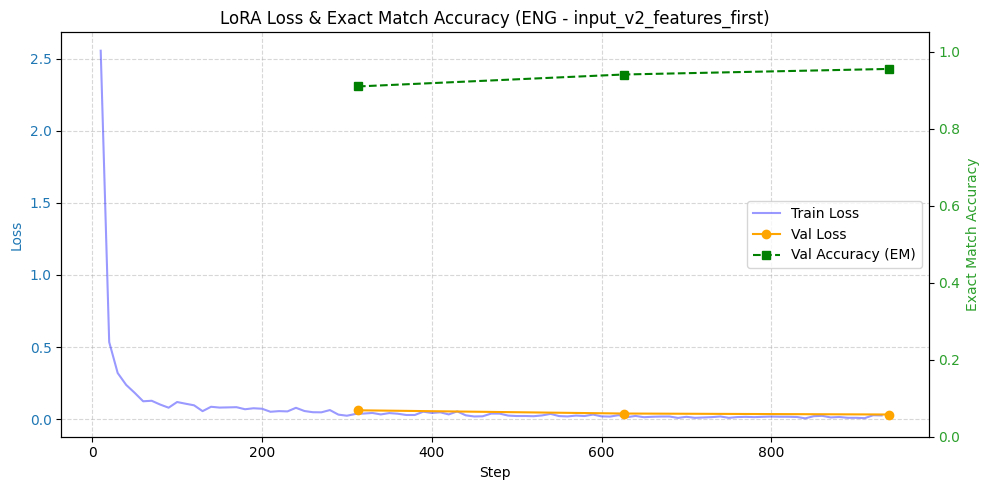

In [30]:
import matplotlib.pyplot as plt
import pandas as pd

if hasattr(trainer, 'state') and trainer.state.log_history:
    df_logs = pd.DataFrame(trainer.state.log_history)
    
    train_df = df_logs[df_logs['loss'].notna()][['step', 'loss']]
    eval_df = df_logs[df_logs['eval_loss'].notna()][['step', 'eval_loss', 'eval_exact_match']]

    fig, ax1 = plt.subplots(figsize=(10, 5))

    # Axis 1: Loss
    ax1.set_xlabel('Step')
    ax1.set_ylabel('Loss', color='tab:blue')
    p1 = ax1.plot(train_df['step'], train_df['loss'], label='Train Loss', color='blue', alpha=0.4)
    p2 = ax1.plot(eval_df['step'], eval_df['eval_loss'], label='Val Loss', color='orange', marker='o')
    ax1.tick_params(axis='y', labelcolor='tab:blue')
    ax1.grid(True, linestyle='--', alpha=0.5)

    # Axis 2: Accuracy
    lines = p1 + p2
    if 'eval_exact_match' in eval_df.columns:
        ax2 = ax1.twinx()
        ax2.set_ylabel('Exact Match Accuracy', color='tab:green')
        p3 = ax2.plot(eval_df['step'], eval_df['eval_exact_match'], label='Val Accuracy (EM)', color='green', marker='s', linestyle='--')
        ax2.tick_params(axis='y', labelcolor='tab:green')
        ax2.set_ylim(0, 1.05)
        lines += p3

    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='center right')
    plt.title(f"LoRA Loss & Exact Match Accuracy ({LANG.upper()} - {INPUT_FORMAT})")
    plt.tight_layout()
    plt.show()

# Zero-Shot Baseline



In [33]:
# Dedicated arguments strictly for evaluation / zero-shot
zero_shot_args = Seq2SeqTrainingArguments(
    output_dir="./zero_shot_eval",
    predict_with_generate=True,
    generation_max_length=MAX_LENGTH,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    fp16=False,
    bf16=torch.cuda.is_bf16_supported(),
    report_to="none"
)

# Load clean base model without training
zero_shot_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

zero_shot_trainer = Seq2SeqTrainer(
    model=zero_shot_model,
    args=zero_shot_args,
    eval_dataset=val_subset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Evaluating Zero-Shot Base Model Performance...")
zero_shot_results = zero_shot_trainer.evaluate()
print(f"Zero-Shot Exact Match Accuracy: {zero_shot_results.get('eval_exact_match', 0.0):.4f}")

Loading weights:   0%|          | 0/172 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Evaluating Zero-Shot Base Model Performance...


Training Loss,Validation Loss,Step,Exact Match
No log,4.343722,0,0.000000


Zero-Shot Exact Match Accuracy: 0.0000


## Rerun the task with Rank = 4
The main goal of our 

In [32]:
# --- 1. Define LoraConfig with r=4 ---
peft_config_r4 = LoraConfig(
    task_type=TaskType.SEQ_2_SEQ_LM,
    r=4,                                # <--- Reduced LoRA rank to 4
    lora_alpha=8,                       # <--- Scaled alpha accordingly (2 * r)
    lora_dropout=0.1,
    bias="none",
    target_modules=["q", "k", "v", "o", "wi_0", "wi_1", "wo"]  # Keep expanded linear layers
)

# Function to instantiate clean base model with r=4 LoRA
def create_lora_r4_model():
    base_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
    lora_model = get_peft_model(base_model, peft_config_r4)
    return lora_model

# --- 2. Initialize fresh r=4 Model ---
model_r4 = create_lora_r4_model()
print("Initialized LoRA model with rank r=4:")
model_r4.print_trainable_parameters()

# --- 3. Set Training Arguments ---
output_dir_name_r4 = f"{LANG}_{MODEL_NAME.replace('/', '_')}_{INPUT_FORMAT}_lora_r4"

training_args_r4 = Seq2SeqTrainingArguments(
    output_dir=os.path.join(MODEL_OUTPUT_DIR, output_dir_name_r4),
    eval_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model='exact_match',
    greater_is_better=True,
    
    learning_rate=3e-3,                 # Same LR as r=16 run
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    num_train_epochs=EPOCHS,            # Same 3 epochs
    logging_steps=10,
    
    predict_with_generate=True,
    generation_max_length=MAX_LENGTH,
    
    fp16=False,
    bf16=torch.cuda.is_bf16_supported()
)

# --- 4. Instantiate Trainer ---
trainer_r4 = Seq2SeqTrainer(
    model=model_r4,
    args=training_args_r4,
    train_dataset=train_subset,         # Using identical dataset slice as r=16 run
    eval_dataset=val_subset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# --- 5. Launch Training ---
print(f"Starting LoRA (r=4) experiment for '{LANG}' using format '{INPUT_FORMAT}'...")
trainer_r4.train()

Loading weights:   0%|          | 0/172 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Initialized LoRA model with rank r=4:
trainable params: 1,564,672 || all params: 301,202,432 || trainable%: 0.5195
Starting LoRA (r=4) experiment for 'eng' using format 'input_v2_features_first'...


Epoch,Training Loss,Validation Loss,Exact Match
1,0.038574,0.057690,0.939500
2,0.023518,0.041988,0.935500
3,0.024844,0.033799,0.954500


TrainOutput(global_step=939, training_loss=0.09069030563703107, metrics={'train_runtime': 778.0848, 'train_samples_per_second': 38.556, 'train_steps_per_second': 1.207, 'total_flos': 1662170360217600.0, 'train_loss': 0.09069030563703107, 'epoch': 3.0})